# F3 · Núcleo algorítmico, eficiencia y programación orientada a objetos

**MCDI500 Programación para la Ciencia de Datos** · Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello
**Proyecto:** Análisis reproducible del Inventario Público de Glaciares de Chile 2022 · **Avance Fase 3 — Semana 2**
**Integrantes:** Francisco Correa Soto · Gustavo Aloy Angella · Roberto Gaubert Urbina · **Docente:** Dr. Omar Salinas Silva

En la Fase 2 construimos un pipeline que funciona: obtiene el inventario de la DGA, lo limpia, imputa, transforma, valida y persiste. Este notebook no cambia los datos ni el pipeline. Cambia la **arquitectura del código**: las mismas operaciones, ahora organizadas en clases que se pueden probar, reemplazar y reutilizar (`src/`). Dentro de ese diseño calcula el resultado principal del proyecto: **cuán concentrada está la superficie glaciar** y por qué la concentración del volumen es una consecuencia de ella.

| Sección | Contenido | Criterio de la pauta |
|---|---|---|
| 0–2 | Entorno, contexto y carga del inventario | II.a |
| 3 | El pipeline de F2 encapsulado en clases | II.b · II.e · III.a |
| 4 | Verificación: ¿las clases reproducen F2? | II.c |
| 5–6 | Concentración de la superficie y volumen como magnitud derivada | II.a · II.e · III.a |
| 7 | Eficiencia: comparación formal de implementaciones | II.d |
| 8 | Recursividad | II.e |
| 9 | Patrones de diseño: Strategy y Observer | III.b |
| 10–11 | Resultados para la Fase 4 y conclusiones | V |

## 0. Entorno, módulos y trazabilidad

Todo el código reutilizable vive en `src/` y se **importa**: este notebook no define clases ni funciones de procesamiento, solo las ejecuta, muestra sus resultados y los interpreta. La raíz del repositorio se localiza desde la carpeta en que Jupyter abra el notebook, así que funciona desde `F3/` o desde la raíz.

In [1]:
import contextlib
import inspect
import io
import sys
import importlib.metadata as metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(c for c in (Path.cwd(), *Path.cwd().parents) if (c / "src" / "utilidades.py").is_file())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

import utilidades as utl           # F1–F2: rutas, huella, carga, pruebas y Bitacora
import limpieza as lim             # funciones de F2 (programación estructurada)
import imputacion as imp           # estrategias de imputación (Strategy)
import transformadores as tr       # Transformador y sus clases hijas
import procesamiento as proc       # arma los pipelines de F2 y verifica las salidas
import concentracion as con        # medidas de concentración
import medicion as me              # medición y comparación de implementaciones
import metadatos as md             # aplanado recursivo e iterativo
from pipeline import Pipeline, RegistroEjecucion, ReporteConsola, ObservadorBitacora

np.random.seed(utl.SEMILLA)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

declaradas = utl.leer_requirements(RAIZ / "requirements.txt")
print("Python:", sys.version.split()[0], "| entorno virtual:", "sí" if sys.prefix != sys.base_prefix else "NO")
for paquete in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    instalada = metadata.version(paquete)
    aviso = "" if instalada == declaradas.get(paquete) else f"  ← requirements.txt declara {declaradas.get(paquete)}"
    print(f"{paquete}: {instalada}{aviso}")
print("Módulos de src/:", sorted(p.name for p in (RAIZ / "src").glob("*.py")))

Python: 3.13.14 | entorno virtual: sí
numpy: 2.5.4
pandas: 3.1.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
Módulos de src/: ['concentracion.py', 'imputacion.py', 'limpieza.py', 'medicion.py', 'metadatos.py', 'pipeline.py', 'procesamiento.py', 'pruebas_concentracion.py', 'pruebas_medicion.py', 'pruebas_nucleo.py', 'transformadores.py', 'utilidades.py']


In [2]:
SALIDAS_F3 = ["F3", "data/processed", "docs/bitacora_f3.md", "docs/metadatos_f3.csv"]   # el propio notebook y sus salidas
print("Repositorio:", utl.version_repositorio(RAIZ, excluir=SALIDAS_F3))
print("Identidad de Git:", utl.identidad_git(RAIZ))

Repositorio: {'rama': 'f3-notebook-gustavo', 'commit': 'b1ca360', 'cambios_sin_commit': True}
Identidad de Git: {'user.name': 'Gustavo Aloy', 'user.email': 'gustavoaloy72@gmail.com', 'email_valido': True}


## 1. Contexto y objetivo de la Fase 3

**Problemática.** Los glaciares son reservas hídricas estratégicas para Chile. La DGA publica el inventario oficial (26.180 glaciares, 45 variables), pero no un cálculo reproducible de cuán concentrada está la superficie glaciar.

**Pregunta de investigación.** ¿Qué tan concentrada está la superficie glaciar en pocos glaciares y regiones, y cambia esa concentración según la clasificación del glaciar?

**Por qué la superficie y no el volumen.** En F2 (sección 2.3) verificamos que el espesor y el volumen **no son mediciones**: la DGA los estimó desde el área con la relación de Chen y Ohmura (1990), `ESP_MED = 28,5 · AREA^0,357`, de modo que `VOL ≈ 0,0285 · AREA^1,357`. La superficie es la magnitud observada; el volumen es una magnitud derivada, y su concentración no puede ser un hallazgo independiente. La sección 6 lo demuestra con datos.

**Qué es la Fase 3.** Es el **núcleo algorítmico** del proyecto: el pipeline de F2 se reorganiza en componentes orientados a objetos sin alterar ningún resultado, se mide su eficiencia y, dentro de ese diseño, se calcula la concentración.

**Integración con lo anterior.**
- *Fase 2:* el pipeline (secciones 3–6 de F2), la regla para elegir la imputación, la bitácora y la función recursiva `aplanar` (F2 sección 7) se trasladan a `src/` sin cambios de lógica.
- *Avance formativo y foro técnico de la semana:* en el foro discutimos cuándo conviene la recursión frente a un bucle y la necesidad de comprobar que dos implementaciones dan el mismo resultado antes de compararlas; ambas ideas se aplican en las secciones 7 y 8. *(⚠ Ajustar con lo que efectivamente discutió el equipo en el foro y en la formativa.)*

## 2. Carga del inventario original

`proc.cargar_original` verifica la huella SHA-256 del CSV de `data/raw/` **antes** de leerlo y se detiene con `ProyectoError` si el archivo no es la versión registrada. El archivo original nunca se modifica: cada paso del pipeline trabaja sobre una copia.

In [3]:
RUTA_ORIGINAL = RAIZ / "data" / "raw" / utl.ARCHIVO_INVENTARIO
original = proc.cargar_original(RAIZ)
huella_inicial = utl.huella_sha256(RUTA_ORIGINAL)
print(f"Inventario: {original.shape[0]:,} filas × {original.shape[1]} columnas | SHA-256 {huella_inicial[:16]}…")

Inventario: 26,180 filas × 45 columnas | SHA-256 5691de5d7d7ffe2c…


## 3. El pipeline de F2 encapsulado en clases

### 3.1 Ejecutar y observar

`proc.verificar_reproduccion` ejecuta los tres pipelines de F2 (limpieza, formato y modelo) con las clases de `src/` y compara sus salidas con las versionadas por F2. Le suscribimos dos observadores: `ReporteConsola` imprime cada paso mientras ocurre y `RegistroEjecucion` lo acumula como tabla. El pipeline no sabe quién lo observa (sección 9).

In [4]:
registro = RegistroEjecucion()
verificacion, limpio, modelo, pipelines = proc.verificar_reproduccion(RAIZ, observadores=[ReporteConsola(), registro])
print(f"\nglaciares_limpio: {limpio.shape} | glaciares_modelo: {modelo.shape}")

  limpieza   DescartadorColumnas                   26180 filas ×  37 col  [0.144 s]
  limpieza   NormalizadorTexto                     26180 filas ×  37 col  [0.297 s]
  limpieza   ConversorTipos                        26180 filas ×  38 col  [0.184 s]
  limpieza   ReconstructorVolumen                  26180 filas ×  40 col  [0.052 s]
  limpieza   MarcadorFaltantes                     26180 filas ×  40 col  [0.014 s]
  limpieza   ImputadorEstrategia(HMIN)             26180 filas ×  41 col  [0.158 s]
  limpieza   ImputadorPuntoMedio(HMEDIA)           26180 filas ×  42 col  [0.011 s]
  limpieza   DerivadorVariables                    26180 filas ×  48 col  [0.028 s]
  formato    Redondeador                           26180 filas ×  48 col  [0.008 s]
  formato    Categorizador                         26180 filas ×  48 col  [0.031 s]
  modelo     CodificadorOrdinal(MZON_GLAC)         26180 filas ×  49 col  [0.061 s]
  modelo     CodificadorOrdinal(CLASE_TAMANO)      26180 filas ×  50 col  [0

Los 15 pasos conservan las 26.180 filas (la clase base lo comprueba en cada paso). La limpieza pasa de 45 a 48 columnas: descarta 9 sin información y agrega banderas y derivadas; el pipeline del modelo agrega ordinales, cíclicas, escaladas y 32 columnas one-hot.

### 3.2 Arquitectura

Cada archivo de `src/` tiene una sola responsabilidad (alta cohesión) y depende solo de los que están por debajo (bajo acoplamiento):

| Archivo | Responsabilidad | Depende de |
|---|---|---|
| `utilidades.py` | Rutas, huella, carga, pruebas y bitácora (F1–F2) | — |
| `limpieza.py` | Funciones de limpieza y codificación (estructuradas, sin estado) | — |
| `imputacion.py` | Estrategias de imputación intercambiables (Strategy) | utilidades |
| `transformadores.py` | Clase base `Transformador` y una clase hija por paso | limpieza, imputacion |
| `pipeline.py` | `Pipeline` (composición) y observadores (Observer) | transformadores |
| `procesamiento.py` | **Única** que conoce la configuración del proyecto: qué pasos, en qué orden | todas las anteriores |
| `concentracion.py` | Medidas de concentración y relación área → volumen | — |
| `medicion.py`, `metadatos.py` | Medición de eficiencia y recursividad | — |

**Prueba operacional del acoplamiento:** para cambiar la estrategia de imputación hay que modificar **un solo archivo** (`procesamiento.py`, o ninguno si se pasa como parámetro, sección 9).

In [5]:
for nombre, pipeline in pipelines.items():
    print(f"Pipeline «{nombre}»: {len(pipeline)} pasos")
    display(pipeline.resumen())

Pipeline «limpieza»: 8 pasos


,orden,paso,clase,clase_base
0,1,DescartadorColumnas,DescartadorColumnas,Transformador
1,2,NormalizadorTexto,NormalizadorTexto,Transformador
2,3,ConversorTipos,ConversorTipos,Transformador
3,4,ReconstructorVolumen,ReconstructorVolumen,Transformador
4,5,MarcadorFaltantes,MarcadorFaltantes,Transformador
5,6,ImputadorEstrategia(HMIN),ImputadorEstrategia,Transformador
6,7,ImputadorPuntoMedio(HMEDIA),ImputadorPuntoMedio,Transformador
7,8,DerivadorVariables,DerivadorVariables,Transformador


Pipeline «formato»: 2 pasos


,orden,paso,clase,clase_base
0,1,Redondeador,Redondeador,Transformador
1,2,Categorizador,Categorizador,Transformador


Pipeline «modelo»: 5 pasos


,orden,paso,clase,clase_base
0,1,CodificadorOrdinal(MZON_GLAC),CodificadorOrdinal,Transformador
1,2,CodificadorOrdinal(CLASE_TAMANO),CodificadorOrdinal,Transformador
2,3,CodificadorCiclico,CodificadorCiclico,Transformador
3,4,EscaladorRobusto,EscaladorRobusto,Transformador
4,5,CodificadorOneHot,CodificadorOneHot,Transformador


### 3.3 Herencia

Todas las clases de paso heredan de `Transformador`, que escribe **una sola vez** lo que comparten: validar la entrada, controlar que se ajuste antes de transformar, copiar el DataFrame antes de modificarlo y comprobar que no se pierdan filas (método plantilla). Cada clase hija implementa solo `aprender` (qué estima de los datos) y `aplicar` (cómo lo usa). La cadena de resolución de métodos (MRO) muestra de dónde hereda cada una:

In [6]:
for paso in (pipelines["limpieza"]["ImputadorEstrategia(HMIN)"], pipelines["modelo"]["EscaladorRobusto"]):
    print(f"{paso.nombre:<28} es Transformador: {isinstance(paso, tr.Transformador)} | MRO: {[c.__name__ for c in type(paso).__mro__]}")
propios = {c.__name__: sorted(m for m in vars(c) if m in ("aprender", "aplicar", "ajustar", "transformar"))
           for c in (tr.ReconstructorVolumen, tr.ImputadorEstrategia, tr.EscaladorRobusto)}
print("Métodos que define cada clase hija:", propios)
print("Métodos que define la clase base:  ", sorted(m for m in ("aprender", "aplicar", "ajustar", "transformar") if m in vars(tr.Transformador)))

ImputadorEstrategia(HMIN)    es Transformador: True | MRO: ['ImputadorEstrategia', 'Transformador', 'object']
EscaladorRobusto             es Transformador: True | MRO: ['EscaladorRobusto', 'Transformador', 'object']
Métodos que define cada clase hija: {'ReconstructorVolumen': ['aplicar', 'aprender'], 'ImputadorEstrategia': ['aplicar', 'aprender'], 'EscaladorRobusto': ['aplicar', 'aprender']}
Métodos que define la clase base:   ['ajustar', 'aplicar', 'aprender', 'transformar']


Las clases hijas no redefinen `ajustar` ni `transformar`: los heredan. Si mañana cambia el control de estado, se modifica en un solo lugar.

### 3.4 Polimorfismo

El bucle de `Pipeline.ajustar_transformar` llama `ajustar` y `transformar` sobre cada paso **sin preguntar de qué clase es**. No hay ningún `if` sobre el tipo: esa ausencia es la evidencia del polimorfismo, y es lo que permite agregar un paso nuevo sin modificar el pipeline (principio de abierto y cerrado).

In [7]:
print(inspect.getsource(Pipeline.ajustar_transformar))

    def ajustar_transformar(self, df):
        """Ajusta cada paso con la salida del anterior y devuelve el resultado final (una pasada)."""
        if not self._pasos:
            raise RuntimeError(f"{self.nombre}: no tiene pasos")
        resultado = df
        for paso in self._pasos:                                   # polimorfismo
            inicio = time.perf_counter()
            resultado = paso.ajustar(resultado).transformar(resultado)
            self._notificar(paso, resultado, time.perf_counter() - inicio, "ajustar_transformar")
        self._ajustado = True
        return resultado



### 3.5 Encapsulamiento

El estado de cada paso es interno (`_parametros`, `_ajustado`, `_evidencia`) y solo se lee mediante propiedades que devuelven **copias**. Dos consecuencias verificables: un uso incorrecto falla con un mensaje claro en vez de producir un resultado sin sentido, y modificar lo que se lee no altera el objeto.

In [8]:
try:
    tr.MarcadorFaltantes().transformar(original)
except RuntimeError as error:
    print("Error esperado al transformar sin ajustar →", error)

paso = pipelines["limpieza"]["ReconstructorVolumen"]
copia = paso.parametros
copia["factor_hielo"] = {"GLACIAR ROCOSO": 999}
print("Factor de hielo tras modificar la copia:", paso.parametros["factor_hielo"])

Error esperado al transformar sin ajustar → MarcadorFaltantes: hay que ajustar antes de transformar
Factor de hielo tras modificar la copia: {'GLACIAR ROCOSO': 0.6}


### 3.6 Qué aprendió cada paso y por qué

Cada transformación conserva la justificación de F2; ahora la evidencia la produce el propio objeto al ejecutarse, no una anotación posterior:

| Paso | Justificación (F2) |
|---|---|
| `DescartadorColumnas` | 100 % vacías, valor único o redundantes; `CH_CASQ` (97,24 % faltante) pasa a bandera |
| `NormalizadorTexto` | Codificación rota (`FOTOGRAMETR├ìA`), mayúsculas y espacios inconsistentes |
| `ConversorTipos` | Coordenadas como texto con coma decimal, fechas en tres formatos, códigos leídos como enteros |
| `ReconstructorVolumen` | 362 volúmenes en 0 por redondeo; se recalculan con la fórmula del inventario, que el paso verifica en los datos |
| `MarcadorFaltantes` + `ImputadorEstrategia` | 33 `HMIN = 0` en tierra o lago son faltantes encubiertos; la estrategia se elige con una regla declarada (sección 9) |
| `ImputadorPuntoMedio` | Un glaciar con `HMEDIA < HMIN`; el punto medio respeta la restricción física |
| `DerivadorVariables` | Asimetría 43 del área → log10; clases de tamaño en la escala del dominio |
| `EscaladorRobusto` | `RANGO_ALT` y `HMEDIA` conservan colas largas: RobustScaler frente a StandardScaler y MinMax |

In [9]:
filas = []
for nombre_pipeline, pipeline in pipelines.items():
    for paso in pipeline.pasos:
        filas.append({"pipeline": nombre_pipeline, "paso": paso.nombre,
                      "evidencia": "; ".join(f"{k} = {v}" for k, v in paso.evidencia.items()) or "—"})
display(pd.DataFrame(filas))

,pipeline,paso,evidencia
0,limpieza,DescartadorColumnas,descartadas = 9; EN_CAMPO_HIELO = 723
1,limpieza,NormalizadorTexto,"valores_corregidos = 139; por_columna = {'NOMBRE': 5, 'FUENTE_DIG': 6, 'NOM_..."
2,limpieza,ConversorTipos,coordenadas_nulas = 0; fechas_completas = 26168; anios = 26180
3,limpieza,ReconstructorVolumen,volumenes = 362; equivalentes = 668
4,limpieza,MarcadorFaltantes,HMIN = 33; HMEDIA = 1
5,limpieza,ImputadorEstrategia(HMIN),metodo = HMEDIA − desnivel mediano por comuna; imputados = 33
6,limpieza,ImputadorPuntoMedio(HMEDIA),imputados = 1
7,limpieza,DerivadorVariables,asimetria_log_area = 0.61; asimetria_log_vol = 0.69
8,formato,Redondeador,—
9,formato,Categorizador,—


## 4. Verificación: ¿las clases reproducen F2?

Si el pipeline con clases produce **exactamente** los mismos archivos que el código de F2, la reorganización no rompió nada. Es la prueba más estricta posible: se comparan las huellas SHA-256 de los CSV, de modo que una diferencia en un solo decimal o en el orden de una columna la haría fallar.

In [10]:
display(verificacion)
assert verificacion["identico"].all(), "Las clases no reproducen F2"
print("Los tres archivos de data/processed son idénticos byte a byte a los de F2.")

,archivo,sha256_F2,sha256_F3,identico
0,glaciares_limpio.csv,ee220b05825da962,ee220b05825da962,True
1,glaciares_modelo.csv,9636c02fccd59e38,9636c02fccd59e38,True
2,perfil_glaciares_limpio.csv,d12e9e68b5f8a70a,d12e9e68b5f8a70a,True


Los tres archivos de data/processed son idénticos byte a byte a los de F2.


Como segunda comprobación, comparamos los DataFrames con `pd.testing.assert_frame_equal`. Hay que indicar `check_dtype=False`: pandas distingue la variante de texto `str` (la del DataFrame en memoria) de `string` (la que aparece al releer el CSV con `cargar_limpio`), aunque los valores sean idénticos. Por eso la comparación byte a byte del archivo es la evidencia principal.

In [11]:
referencia_f2 = utl.cargar_limpio(RAIZ / "data" / "processed" / "glaciares_limpio.csv")
pd.testing.assert_frame_equal(limpio, referencia_f2, check_dtype=False, check_categorical=False)
print("assert_frame_equal: mismos valores, columnas e índice que glaciares_limpio.csv de F2")

assert_frame_equal: mismos valores, columnas e índice que glaciares_limpio.csv de F2


**Pruebas del núcleo.** `src/pruebas_nucleo.py` reúne 29 pruebas de los transformadores, las estrategias y el pipeline en los tres escenarios que pide la pauta: casos normales (el flujo esperado), casos límite (una fila, columna sin nulos, escala constante, grupo no visto) y excepciones (transformar sin ajustar, columna ausente, tipo equivocado, paso que pierde filas).

In [12]:
import pruebas_nucleo
resultado_nucleo = utl.ejecutar_pruebas(pruebas_nucleo.pruebas())
display(resultado_nucleo)
assert resultado_nucleo["resultado"].eq("OK").all(), "Hay pruebas del núcleo fallidas"
print(f"{len(resultado_nucleo)}/{len(resultado_nucleo)} OK:", resultado_nucleo["tipo"].value_counts().to_dict())

,tipo,prueba,resultado
0,normal,"DescartadorColumnas quita vacías, WGI_1 y OBJECTID y crea EN_CAMPO_HIELO",OK
1,normal,NormalizadorTexto repara 'FOTOGRAMETR├ìA' y cuenta los cambios,OK
2,normal,ReconstructorVolumen aplica AREA·ESP/1000 y marca la bandera,OK
3,normal,MarcadorFaltantes respeta el cero en fiordo y marca el de tierra,OK
4,normal,Strategy: el imputador elige la estrategia sin violaciones y respeta HMIN ≤ ...,OK
5,normal,Strategy: cambiar la estrategia no modifica la clase que imputa,OK
6,normal,Lo aprendido en ajustar se aplica a otro conjunto (sin fuga de datos),OK
7,normal,CodificadorOneHot no crea columnas para categorías no vistas al ajustar,OK
8,normal,Observer: el pipeline notifica un evento por paso,OK
9,normal,Ningún paso modifica el DataFrame de entrada,OK


29/29 OK: {'excepción': 13, 'normal': 11, 'límite': 5}


## 5. Resultado principal: concentración de la superficie

Tres medidas responden la pregunta, cada una como clase hija de `MedidaConcentracion`:

- **Participación de los mayores:** % de la superficie que reúne el 1 % (261) y el 10 % (2.618) de los glaciares más grandes.
- **Índice de Gini:** 0 si todos los glaciares tuvieran la misma superficie; cercano a 1 si uno solo la concentrara.
- **Curva de Lorenz:** la versión gráfica del Gini.

`AnalisisConcentracion` aplica cualquier lista de medidas a una magnitud sin preguntar su tipo (polimorfismo, igual que el pipeline).

In [13]:
superficie = con.AnalisisConcentracion(limpio, "AREA_KM2", con.medidas_proyecto())
resumen_superficie = superficie.resumen()
display(pd.DataFrame([resumen_superficie]).round(3))

,magnitud,glaciares,total,pct_1%_mayores,pct_10%_mayores,gini
0,AREA_KM2,26180,21012.341,71.525,91.096,0.937


**Interpretación.** El 1 % de los glaciares (261) reúne el **71,5 %** de los 21.012 km² de superficie glaciar del país, y el 10 % reúne el **91,1 %**. El Gini de **0,937** es extremo: el 90 % restante de los glaciares, más de 23.000, aporta menos de una décima parte de la superficie.

### 5.1 Por región

In [14]:
por_region = superficie.por_grupo("REGION")
display(por_region.round(3))
dos_mayores = por_region["pct"].iloc[:2].sum()
print(f"{' y '.join(por_region.index[:2])}: {dos_mayores:.1f} % de la superficie")

,glaciares,total,pct,pct_acumulado,pct_1%_mayores,pct_10%_mayores,gini
REGION,,,,,,,
MAGALLANES Y ANTARTICA CHILENA,7055,10426.606,49.621,49.621,67.557,92.652,0.944
AYSEN DEL GENERAL CARLOS IBAÑEZ DEL CAMPO,10301,8723.680,41.517,91.138,76.274,92.371,0.949
LOS LAGOS,3025,614.545,2.925,94.063,30.482,75.955,0.843
METROPOLITANA DE SANTIAGO,1254,450.378,2.143,96.206,25.542,69.233,0.773
LIBERTADOR BERNARDO O HIGGINS,776,269.771,1.284,97.490,39.749,76.672,0.842
VALPARAISO,765,161.939,0.771,98.261,27.607,59.400,0.709
ATACAMA,863,91.971,0.438,98.699,17.537,57.446,0.685
COQUIMBO,898,84.100,0.400,99.099,11.971,48.658,0.625
ARAUCANIA,115,56.176,0.267,99.366,18.547,74.526,0.855


MAGALLANES Y ANTARTICA CHILENA y AYSEN DEL GENERAL CARLOS IBAÑEZ DEL CAMPO: 91.1 % de la superficie


Magallanes y Aysén, donde están los Campos de Hielo Norte y Sur, reúnen el **91,1 %** de la superficie. Dentro de esas dos regiones la concentración también es extrema (Gini 0,94–0,95); en las regiones del norte es menor (0,50–0,69), porque predominan glaciares pequeños de tamaño parecido.

### 5.2 Por clasificación: ¿cambia la concentración según el tipo de glaciar?

In [15]:
por_clase = superficie.por_grupo("CLASIFICA")
por_clase.insert(1, "pct_glaciares", 100 * por_clase["glaciares"] / por_clase["glaciares"].sum())
display(por_clase.round(3))

,glaciares,pct_glaciares,total,pct,pct_acumulado,pct_1%_mayores,pct_10%_mayores,gini
CLASIFICA,,,,,,,,
GLACIAR EFLUENTE,217,0.829,13737.600,65.379,65.379,11.179,57.684,0.709
GLACIAR DE MONTAÑA,3844,14.683,4128.051,19.646,85.025,10.415,40.589,0.499
GLACIAR DE VALLE,310,1.184,1870.420,8.902,93.926,9.308,40.482,0.535
GLACIARETE,18211,69.561,792.202,3.770,97.696,5.549,41.485,0.602
GLACIAR ROCOSO,3598,13.743,484.068,2.304,100.000,11.844,46.490,0.594


**Sí cambia, y es la parte más informativa del resultado.**

- Los **glaciares efluentes** (que descienden desde los campos de hielo) son el 0,8 % de los glaciares (217) y reúnen el **65,4 %** de la superficie.
- Los **glaciaretes** son el 69,6 % de los glaciares (18.211) y aportan solo el **3,8 %**.
- **Dentro** de cada clasificación el Gini es moderado (0,50 a 0,71), mientras que en el total es 0,937. Gran parte de la concentración se explica por el **tipo** de glaciar: pocos glaciares de un tipo muy grande frente a muchos de tipos pequeños.

### 5.3 Curva de Lorenz de la superficie

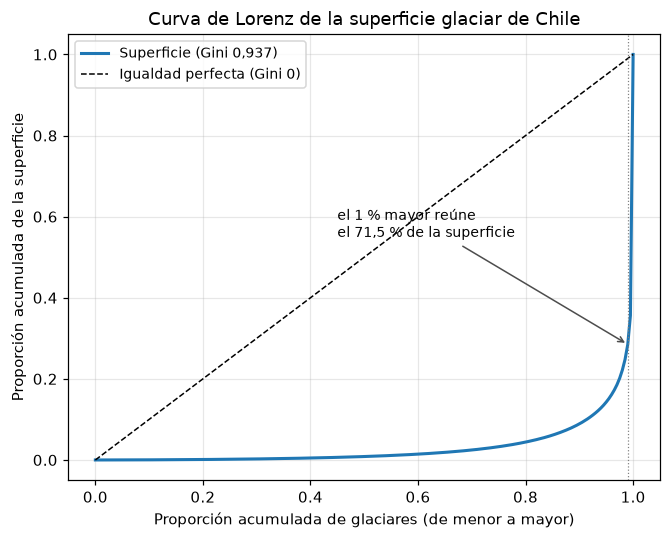

In [16]:
curva_superficie = superficie.curva()
fig, eje = plt.subplots(figsize=(6.2, 5))
eje.plot(curva_superficie["prop_glaciares"], curva_superficie["prop_magnitud"], color="tab:blue", lw=2,
         label=f"Superficie (Gini {resumen_superficie['gini']:.3f})".replace(".", ","))
eje.plot([0, 1], [0, 1], "k--", lw=1, label="Igualdad perfecta (Gini 0)")
eje.axvline(0.99, color="0.5", lw=0.8, ls=":")
eje.annotate("el 1 % mayor reúne\nel 71,5 % de la superficie", xy=(0.99, 1 - 0.715), xytext=(0.45, 0.55),
             arrowprops={"arrowstyle": "->", "color": "0.3"}, fontsize=9)
eje.set(xlabel="Proporción acumulada de glaciares (de menor a mayor)", ylabel="Proporción acumulada de la superficie",
        title="Curva de Lorenz de la superficie glaciar de Chile")
eje.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

La curva se mantiene casi pegada al eje horizontal hasta el 90 % de los glaciares y sube bruscamente al final: la superficie está en la cola de glaciares grandes.

### 5.4 La jerarquía de las medidas

`MedidaConcentracion` es un segundo ejemplo de los tres principios. Su método `calcular` valida una sola vez (sin nulos, sin negativos, conjunto no vacío) y delega en `_calcular`, que cada clase hija implementa:

In [17]:
for medida in [*con.medidas_proyecto(), con.CurvaLorenz()]:
    print(f"{medida!r:<30} etiqueta = {medida.etiqueta:<18} MRO: {[c.__name__ for c in type(medida).__mro__][:-1]}")
try:
    con.IndiceGini().calcular([1.0, -2.0])
except ValueError as error:
    print("Validación heredada de la clase base →", error)

ParticipacionMayores(0.01)     etiqueta = pct_1%_mayores     MRO: ['ParticipacionMayores', 'MedidaConcentracion']
ParticipacionMayores(0.1)      etiqueta = pct_10%_mayores    MRO: ['ParticipacionMayores', 'MedidaConcentracion']
IndiceGini()                   etiqueta = gini               MRO: ['IndiceGini', 'MedidaConcentracion']
CurvaLorenz()                  etiqueta = lorenz             MRO: ['CurvaLorenz', 'MedidaConcentracion']
Validación heredada de la clase base → gini: hay valores negativos


## 6. El volumen como magnitud derivada

El volumen del inventario no se midió: se calculó desde el área. Si su concentración fuera un hallazgo independiente, el volumen calculado **solo con la superficie** debería concentrarse de otra forma. `con.comparar_magnitudes` lo comprueba con tres magnitudes:

1. `AREA_KM2`: la superficie (observada).
2. `VOL_km3`: el volumen publicado por la DGA.
3. `VOL_DESDE_AREA`: un volumen que calculamos con `0,0285 · AREA^1,357` (× 0,6 en glaciares rocosos), sin usar ningún otro dato.

In [18]:
magnitudes = con.comparar_magnitudes(limpio, con.medidas_proyecto())
display(magnitudes.round(3))
fila = magnitudes.set_index("magnitud")
assert np.isclose(fila.loc["VOL_km3", "gini"], fila.loc["VOL_DESDE_AREA", "gini"], atol=5e-4)
print(f"Correlación entre el volumen publicado y el calculado desde el área: "
      f"{np.corrcoef(limpio['VOL_km3'], con.volumen_desde_area(limpio))[0, 1]:.6f}")

,magnitud,glaciares,total,pct_1%_mayores,pct_10%_mayores,gini
0,AREA_KM2,26180,21012.341,71.525,91.096,0.937
1,VOL_km3,26180,3026.198,93.780,99.085,0.991
2,VOL_DESDE_AREA,26180,3026.197,93.780,99.085,0.991


Correlación entre el volumen publicado y el calculado desde el área: 1.000000


**El volumen calculado solo desde la superficie reproduce exactamente la concentración del volumen publicado** (93,8 % en el 1 % mayor, 99,1 % en el 10 % y Gini 0,991). La concentración del volumen no contiene información adicional: es la de la superficie, **amplificada** por el exponente.

**Por qué se amplifica.** Como 1,357 > 1, el volumen crece más rápido que el área: multiplicar la superficie por *k* multiplica el volumen por *k*^1,357.

In [19]:
for k in (2, 10, 100):
    print(f"Un glaciar {k:>3} veces más extenso tiene {k ** con.EXPONENTE_VOLUMEN:,.1f} veces más volumen")

Un glaciar   2 veces más extenso tiene 2.6 veces más volumen
Un glaciar  10 veces más extenso tiene 22.8 veces más volumen
Un glaciar 100 veces más extenso tiene 517.6 veces más volumen


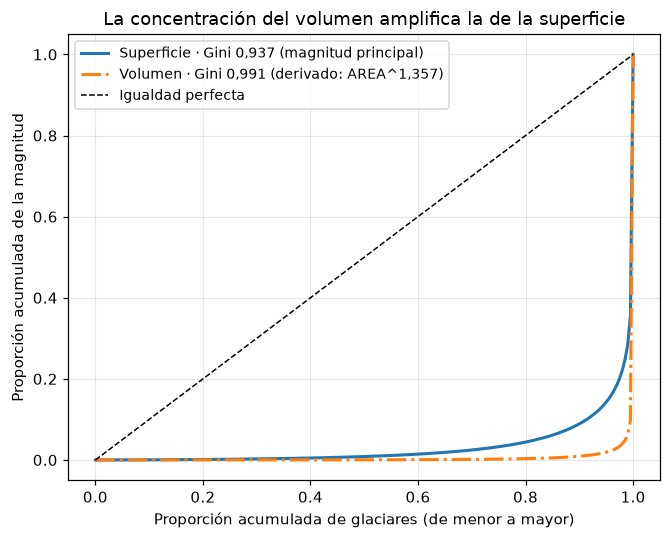

In [20]:
curva_volumen = con.AnalisisConcentracion(limpio, "VOL_km3", con.medidas_proyecto()).curva()
fig, eje = plt.subplots(figsize=(6.2, 5))
eje.plot(curva_superficie["prop_glaciares"], curva_superficie["prop_magnitud"], color="tab:blue", lw=2,
         label=f"Superficie · Gini {fila.loc['AREA_KM2', 'gini']:.3f}".replace(".", ",") + " (magnitud principal)")
eje.plot(curva_volumen["prop_glaciares"], curva_volumen["prop_magnitud"], color="tab:orange", lw=2, ls="-.",
         label=f"Volumen · Gini {fila.loc['VOL_km3', 'gini']:.3f}".replace(".", ",") + " (derivado: AREA^1,357)")
eje.plot([0, 1], [0, 1], "k--", lw=1, label="Igualdad perfecta")
eje.set(xlabel="Proporción acumulada de glaciares (de menor a mayor)", ylabel="Proporción acumulada de la magnitud",
        title="La concentración del volumen amplifica la de la superficie")
eje.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Conclusión.** El resultado del proyecto es la concentración de la **superficie**. La del volumen se reporta como magnitud derivada: es mayor porque el volumen es una función convexa del área, no porque exista un segundo fenómeno. Por la misma razón el proyecto no estudia relaciones entre área y volumen (F1, fuera del alcance).

Las pruebas de `src/pruebas_concentracion.py` fijan estas cifras como **cifras de control**: si un cambio en el código las alterara, la prueba fallaría.

In [21]:
import pruebas_concentracion
resultado_concentracion = utl.ejecutar_pruebas(pruebas_concentracion.pruebas())
display(resultado_concentracion)
assert resultado_concentracion["resultado"].eq("OK").all(), "Hay pruebas de concentración fallidas"
print(f"{len(resultado_concentracion)}/{len(resultado_concentracion)} OK:", resultado_concentracion["tipo"].value_counts().to_dict())

,tipo,prueba,resultado
0,normal,"Participación del 50 % mayor en [1, 2, 3, 4] = 70 %",OK
1,normal,"Gini de [1, 2, 3, 4] = 0,25",OK
2,normal,"Lorenz empieza en (0, 0) y termina en (1, 1)",OK
3,normal,Polimorfismo: el análisis acepta cualquier MedidaConcentracion,OK
4,normal,por_grupo suma 100 % y está ordenado de mayor a menor,OK
5,límite,Gini de valores iguales = 0,OK
6,límite,Gini con un solo glaciar con todo = (n − 1) / n,OK
7,límite,Participación con fracción 1 = 100 %,OK
8,límite,Un solo valor: Gini 0 y Lorenz de dos puntos,OK
9,límite,El análisis no modifica el DataFrame recibido,OK


24/24 OK: {'excepción': 10, 'normal': 5, 'límite': 5, 'control': 4}
